In [14]:
! uv pip install -q -r ..\requirements.txt

In [48]:
import numpy as np 
import pandas as pd 
import matplotlib as mp 
import matplotlib.pyplot as plt
import re
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV




In [16]:
def load_dataset():
    train = pd.read_csv("../data/train.csv")
    test = pd.read_csv("../data/test.csv")
    return train,test

train ,test = load_dataset()
print(train.shape,test.shape)
print(train.dtypes)
print(train.isnull().sum())

(188533, 13) (125690, 12)
id              int64
brand             str
model             str
model_year      int64
milage          int64
fuel_type         str
engine            str
transmission      str
ext_col           str
int_col           str
accident          str
clean_title       str
price           int64
dtype: object
id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0
transmission        0
ext_col             0
int_col             0
accident         2452
clean_title     21419
price               0
dtype: int64


In [17]:
train.describe()

,id,model_year,milage,price
count,188533.000000,188533.000000,188533.000000,1.885330e+05
mean,94266.000000,2015.829998,65705.295174,4.387802e+04
std,54424.933488,5.660967,49798.158076,7.881952e+04
min,0.000000,1974.000000,100.000000,2.000000e+03
25%,47133.000000,2013.000000,24115.000000,1.700000e+04
50%,94266.000000,2017.000000,57785.000000,3.082500e+04
75%,141399.000000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


## Dropping ID column since its not required

In [18]:
train = train.drop(columns=['id'])

# fuel_type: garbage values ko NaN bana do, phir missing ko "Unknown" se fill karo
train["fuel_type"] = train["fuel_type"].replace(["-","not supported"],np.nan)
train["fuel_type"]  = train["fuel_type"].fillna("Unknown")

# accident : treat missing as unknown
train["accident"] = train["accident"].fillna("Unknown")

# clean_title: NaN ka matlab likely "No" hai (sirf Yes value dataset me hai)
train["clean_title"] = train["clean_title"].fillna("No")

print(train.isnull().sum())  

brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64


### remove Usefull Numbers from Engine column (Feature Engineering)

In [19]:
def extract_hp(text):
    match = re.search(r'(\d+\.?\d*)HP', text)
    return float(match.group(1)) if match else np.nan


def extract_liters(text):
    match = re.search(r'(\d+\.?\d*)L', text)
    return float(match.group(1)) if match else np.nan

train["engine_hp"] = train["engine"].apply(extract_hp)
train["engine_liters"] = train["engine"].apply(extract_liters)

print(train[["engine","engine_hp","engine_liters"]].head(10))
print("Missing HP:", train["engine_hp"].isnull().sum())
print("Missing Liters:", train["engine_liters"].isnull().sum())

                                              engine  engine_hp  engine_liters
0       172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel      172.0            1.6
1       252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel      252.0            3.9
2  320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...      320.0            5.3
3       420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel      420.0            5.0
4       208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel      208.0            2.0
5       252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel      252.0            2.0
6      333.0HP 3.0L V6 Cylinder Engine Gasoline Fuel      333.0            3.0
7  355.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...      355.0            5.3
8                    2.7L V6 24V PDI DOHC Twin Turbo        NaN            2.7
9  425.0HP 3.0L Straight 6 Cylinder Engine Gasoli...      425.0            3.0
Missing HP: 33259
Missing Liters: 14214


In [20]:
# brand-wise median se fill karo (zyada accurate)
train["engine_hp"] = train.groupby("brand")["engine_hp"].transform(
    lambda x: x.fillna(x.median())
)
train["engine_liters"] = train.groupby("brand")["engine_liters"].transform(
    lambda x: x.fillna(x.median())
)

# agar kisi brand ka poora group hi NaN tha, to global median se fallback
train["engine_hp"] = train["engine_hp"].fillna(train["engine_hp"].median())
train["engine_liters"] = train["engine_liters"].fillna(train["engine_liters"].median())

print("Missing HP after fix:", train["engine_hp"].isnull().sum())
print("Missing Liters after fix:", train["engine_liters"].isnull().sum())

train = train.drop(columns=["engine"])

Missing HP after fix: 0
Missing Liters after fix: 0


In [21]:
train['car_age'] = 2024 - train["model_year"]
train = train.drop(columns=["model_year"])
print(train["car_age"].describe())

count    188533.000000
mean          8.170002
std           5.660967
min           0.000000
25%           4.000000
50%           7.000000
75%          11.000000
max          50.000000
Name: car_age, dtype: float64


In [22]:
def simplify_transmission(t):
    t = str(t).lower()
    if "m/t" in t or "manual" in t:
        return "Manual"
    elif "cvt" in t:
        return "CVT"
    elif "a/t" in t or "automatic" in t or "dual shift" in t:
        return "Automatic"
    else:
        return "Other"

train["transmission_simple"] = train["transmission"].apply(simplify_transmission)
train = train.drop(columns=["transmission"])

print(train["transmission_simple"].value_counts())

transmission_simple
Automatic    168728
Manual        16358
CVT            2834
Other           613
Name: count, dtype: int64


In [23]:
# brand: rare brands ko "Other" bana do
brand_counts = train["brand"].value_counts()
rare_brands = brand_counts[brand_counts < 500].index
train["brand"] = train["brand"].replace(rare_brands, "Other")

# model: top 50 models rakho, baaki "Other"
top_models = train["model"].value_counts().nlargest(50).index
train["model"] = train["model"].where(train["model"].isin(top_models), "Other")

# colors: same treatment
for col in ["ext_col", "int_col"]:
    top_vals = train[col].value_counts().nlargest(20).index
    train[col] = train[col].where(train[col].isin(top_vals), "Other")

print(train["brand"].nunique(), train["model"].nunique(), train["ext_col"].nunique(), train["int_col"].nunique())

41 51 21 21


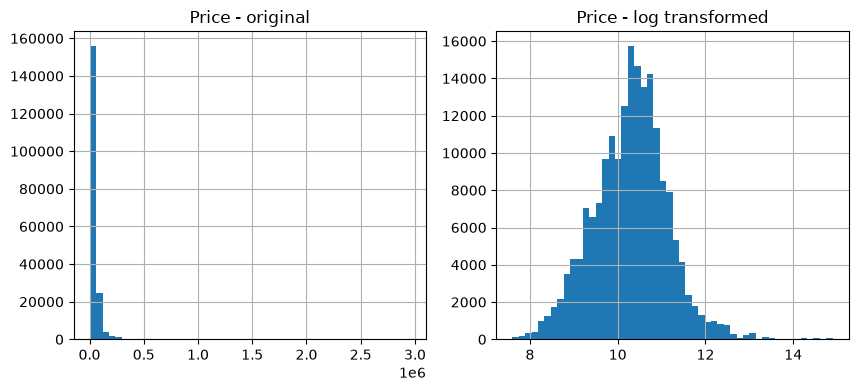

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(10,4))
train["price"].hist(bins=50, ax=axes[0])
axes[0].set_title("Price - original")

np.log1p(train["price"]).hist(bins=50, ax=axes[1])
axes[1].set_title("Price - log transformed")
plt.show()

train["price_log"] = np.log1p(train["price"])

In [25]:
Q1 = train["price"].quantile(0.25)
Q3 = train["price"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 3 * IQR

print("Upper limit:", upper_limit)
print("Rows beyond limit:", (train["price"] > upper_limit).sum())

train = train[train["price"] <= upper_limit]

Upper limit: 148600.0
Rows beyond limit: 5402


In [26]:
categorical_cols = ["brand", "model", "fuel_type", "ext_col", "int_col",
                     "accident", "clean_title", "transmission_simple"]

train_encoded = pd.get_dummies(train, columns=categorical_cols, drop_first=True)

print(train_encoded.shape)

(183131, 148)


In [32]:

numeric_cols = ["milage", "engine_hp", "engine_liters", "car_age"]

scaler = StandardScaler()
train_encoded[numeric_cols] = scaler.fit_transform(train_encoded[numeric_cols])

print(train_encoded[numeric_cols].describe())

             milage     engine_hp  engine_liters       car_age
count  1.831310e+05  1.831310e+05   1.831310e+05  1.831310e+05
mean   1.308326e-16 -1.022760e-16  -2.758658e-16  7.558181e-17
std    1.000003e+00  1.000003e+00   1.000003e+00  1.000003e+00
min   -1.347461e+00 -2.522159e+00  -2.365698e+00 -1.461461e+00
25%   -8.363961e-01 -6.565531e-01  -5.877605e-01 -7.551014e-01
50%   -1.522929e-01 -6.888732e-02  -2.094759e-01 -2.253315e-01
75%    5.916291e-01  5.560906e-01   6.984070e-01  4.810283e-01
max    6.799403e+00  6.339468e+00   3.497713e+00  7.368036e+00


In [34]:
X  = train_encoded.drop(columns=["price","price_log"])
y = train_encoded["price_log"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_val.shape)

(146504, 146) (36627, 146)


### train the Model

In [41]:
model = LinearRegression()
model.fit(X_train,y_train)

preds_log = model.predict(X_val)
preds = np.expm1(preds_log)          # wapas original ₹ scale me
actual = np.expm1(y_val)

rmse = np.sqrt(mean_squared_error(actual, preds))
r2 = r2_score(actual, preds)

print("RMSE:", rmse)
print("R²:", r2)

RMSE: 17722.508382272907
R²: 0.5302812443964056


In [45]:

# Random Forest
rf = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_preds_log = rf.predict(X_val)
rf_preds = np.expm1(rf_preds_log)
actual = np.expm1(y_val)

rf_rmse = np.sqrt(mean_squared_error(actual, rf_preds))
rf_r2 = r2_score(actual, rf_preds)

print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²:", rf_r2)

Random Forest RMSE: 17123.55775091066
Random Forest R²: 0.5614940138362059


In [46]:
rf2 = RandomForestRegressor(n_estimators=300, max_depth=25, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf2.fit(X_train, y_train)
preds = np.expm1(rf2.predict(X_val))
print("RMSE:", np.sqrt(mean_squared_error(actual, preds)))
print("R²:", r2_score(actual, preds))

RMSE: 17252.83720196709
R²: 0.5548477534732436


In [47]:
train_preds = np.expm1(rf2.predict(X_train))
train_actual = np.expm1(y_train)
print("Train R²:", r2_score(train_actual, train_preds))
print("Val R²:", r2_score(actual, rf_preds))  # ya jo bhi tumne last print kiya

Train R²: 0.799893198240897
Val R²: 0.5614940138362059


In [49]:

params = {"max_depth": [8, 12, 15], "min_samples_leaf": [5, 10, 20]}
grid = GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
                     params, cv=3, scoring="r2")
grid.fit(X_train, y_train)
print(grid.best_params_, grid.best_score_)

{'max_depth': 15, 'min_samples_leaf': 10} 0.6897257415650845


In [51]:
! pip install xgboost

  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/2f/3c/925394671f6a1668e2a71886de66e80be694eaf37f615cec74eefaf43107/xgboost-3.4.1-py3-none-win_amd64.whl.metadata
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB 330.3 kB/s eta 0:02:29
   ---------------------------------------- 0.0/48.9 MB 330.3 kB/s eta 0:02:29
   ---------------------------------------- 0.1/48.9 MB 655.4 kB/s eta 0:01:15
   ---------------------------------------- 0.2/48.9 MB 893.0 kB/s eta 0:00:55
   ---------------------------------------- 0.3/48.9 MB 1.2 MB/s eta 0:00:41
   ---------------------------------------- 0.3/48.9 MB 1.4 MB/s eta 0:00:35
   ---------------------------------------- 0.4/48.9 MB 1.5 MB/s eta 0:00:33
   ---------------------------------------- 0.5/48.9 MB 1.6 MB/s eta 0:00:31
    ---------------------------


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
# pip install xgboost
from xgboost import XGBRegressor
xgb = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42)
xgb.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [53]:
best_rf = grid.best_estimator_
val_preds = np.expm1(best_rf.predict(X_val))
print("Tuned RF - RMSE:", np.sqrt(mean_squared_error(actual, val_preds)))
print("Tuned RF - R²:", r2_score(actual, val_preds))

Tuned RF - RMSE: 17062.128607383103
Tuned RF - R²: 0.5646345679778948


In [54]:
xgb_val_preds = np.expm1(xgb.predict(X_val))
print("XGBoost - RMSE:", np.sqrt(mean_squared_error(actual, xgb_val_preds)))
print("XGBoost - R²:", r2_score(actual, xgb_val_preds))

XGBoost - RMSE: 17037.753671288574
XGBoost - R²: 0.5658776044921456


In [55]:
import joblib
joblib.dump(xgb, "car_price_model.pkl")
joblib.dump(scaler, "scaler.pkl")  # scaling bhi save karo, prediction time pe zaroori hoga

['scaler.pkl']